# Proyecto Final — Minería de Datos 1
## Dataset 2: Agentes de ventas (`Employee_Performance_Imputed_Distribution`)

**Colegio Universitario de Cartago — Tecnologías de Información, Big Data MD1-152**<br>
Profesor: Ronald Córdoba Vega

**Grupo #1:** Derek Barrantes Torres · Jeriel Eduardo Fonseca Ramírez · Sebastián Flores Figueroa · Jeremy Ramírez Pérez · Samiel Jiménez Portuguez

Este notebook desarrolla los **puntos 1 y 2** del enunciado a partir de los datos limpios del grupo (limpieza de Derek Barrantes):

1. Cargar el set de datos y describir los tipos de variables y su uso en el análisis (**diccionario de variables**).
2. Construir la parte exploratoria (**EDA**) y explicarla.

Las conclusiones del final indican qué variables se usarán en la clusterización (punto 3).

**Archivo necesario en esta misma carpeta:** `empleados_limpio.csv`.

## 1. Librerías y configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

## 2. Carga del set de datos

Cada fila es un **empleado** de la empresa, con sus datos demográficos, su puesto, sus escalas de satisfacción, su trayectoria, su calificación de desempeño, un conjunto de métricas comerciales y si dejó o no la empresa (`rotacion`).

In [2]:
df = pd.read_csv("empleados_limpio.csv")
print(f"Registros: {df.shape[0]}  |  Variables: {df.shape[1]}")
df.head()

Registros: 1200  |  Variables: 55


,emp_id,edad,genero,area_estudio,estado_civil,departamento,cargo,frecuencia_viaje,distancia_casa,nivel_educativo,sat_ambiente,tarifa_hora,involucramiento,nivel_cargo,sat_trabajo,n_empresas,horas_extra,aumento_salarial_pct,sat_relaciones,exp_total_anios,capacitaciones_ult_anio,balance_vida_trabajo,anios_empresa,anios_rol,anios_desde_ascenso,anios_con_gerente,calificacion_desempeno,contactos_dia,demos_dia,tiempo_interaccion_seg,ventas_dia,valor_venta_prom,feedback_cliente,salario_anual,tasa_conversion,pct_ventas_alto_valor,interacciones_por_cliente,conocimiento_producto,prop_clientes_m_vs_f,rotacion,genero_m,horas_extra_bin,rotacion_bin,viaje_ord,estudio_Human Resources,estudio_Life Sciences,estudio_Marketing,estudio_Medical,estudio_Other,estudio_Technical Degree,civil_Divorced,civil_Married,civil_Single,es_ventas,es_agente_ventas
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,4,55,3,2,4,1,No,12,4,10,2,2,10,7,0,8,3,118.392243,39.170208,1273.774250,3,40096.77000,3.781753,195769,0.104787,0.229816,1.961721,79.497775,0.415024,No,1,0,0,1,0,0,1,0,0,0,0,0,1,1,1
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,4,42,3,2,1,2,No,12,4,20,2,3,7,7,1,7,3,89.340829,2.508795,404.440211,3,16918.86777,2.865392,212194,0.470160,0.448324,1.733028,66.959862,0.411644,No,1,0,0,1,0,0,1,0,0,0,0,0,1,1,1
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,4,48,2,3,1,5,Yes,21,3,20,2,3,18,13,1,12,4,81.512099,16.474422,741.838361,1,232745.48780,3.722888,173590,0.290968,0.146805,1.629473,74.003103,0.415218,No,1,1,0,2,0,1,0,0,0,0,0,1,0,1,1
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,2,73,2,5,4,3,No,15,2,23,2,2,21,6,12,6,3,60.879884,7.871196,1305.452519,4,351944.31070,4.395204,109538,0.271255,0.286976,4.735974,65.882153,0.352787,No,1,0,0,1,1,0,0,0,0,0,1,0,0,0,0
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,1,84,3,2,1,8,No,14,4,10,1,3,2,2,2,2,3,60.431830,1.464253,1221.332063,4,33871.45925,3.161762,105672,0.167018,0.824831,2.649225,66.272329,0.514202,No,1,0,0,1,0,0,1,0,0,0,0,0,1,1,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 55 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   emp_id                     1200 non-null   str    
 1   edad                       1200 non-null   int64  
 2   genero                     1200 non-null   str    
 3   area_estudio               1200 non-null   str    
 4   estado_civil               1200 non-null   str    
 5   departamento               1200 non-null   str    
 6   cargo                      1200 non-null   str    
 7   frecuencia_viaje           1200 non-null   str    
 8   distancia_casa             1200 non-null   int64  
 9   nivel_educativo            1200 non-null   int64  
 10  sat_ambiente               1200 non-null   int64  
 11  tarifa_hora                1200 non-null   int64  
 12  involucramiento            1200 non-null   int64  
 13  nivel_cargo                1200 non-null   int64  
 14  sat

**Interpretación:** la tabla limpia tiene **1200 empleados y 55 variables** y no hay valores nulos. Hay 36 columnas enteras, 10 decimales y 9 de texto. Varias columnas enteras (escalas de satisfacción de 1 a 4, nivel del puesto, desempeño) son en realidad **ordinales** y otras son variables de 0 y 1 creadas en la limpieza, así que no deben tratarse como cantidades. En el archivo original, las métricas comerciales tenían nombres largos y con un formato distinto al resto (la limpieza los normalizó), lo que sugiere que se **agregaron al set original** desde otra fuente.

## 3. Diccionario de variables

Las 55 variables se organizan en grupos temáticos. Para cada una se indica su **nombre original**, su **tipo estadístico**, su **rango**, una **descripción** y el **uso** que tendrá en el análisis.

In [4]:
uso_cluster = "Candidata para la clusterización (escalada)."
uso_perfil = "Descriptiva: perfilar los grupos resultantes."
uso_comercial = "Candidata; su calidad se valida en la sección 6.7."
creada = "(creada en la limpieza)"

diccionario_base = [
    # (variable limpia, variable original, grupo, tipo estadístico, descripción, uso)
    ("emp_id", "EmpNumber", "Identificación", "Identificador", "Código único del empleado.", "Solo identifica registros; se excluye."),
    ("edad", "Age", "Demográfica", "Numérica discreta", "Edad en años.", uso_cluster),
    ("genero", "Gender", "Demográfica", "Categórica nominal (binaria)", "Género: Male o Female.", uso_perfil),
    ("area_estudio", "EducationBackground", "Demográfica", "Categórica nominal",
     "Área de formación académica (Life Sciences, Medical, Marketing, Technical Degree, Human Resources, Other).", uso_perfil),
    ("estado_civil", "MaritalStatus", "Demográfica", "Categórica nominal", "Estado civil: Single, Married o Divorced.", uso_perfil),
    ("departamento", "EmpDepartment", "Puesto y organización", "Categórica nominal",
     "Departamento: Sales, Development, Research & Development, Human Resources, Finance o Data Science.", uso_perfil),
    ("cargo", "EmpJobRole", "Puesto y organización", "Categórica nominal (alta cardinalidad)",
     "Puesto de trabajo (19 valores).", uso_perfil),
    ("frecuencia_viaje", "BusinessTravelFrequency", "Puesto y organización", "Categórica ordinal",
     "Frecuencia de viajes de trabajo: Non-Travel, Travel_Rarely o Travel_Frequently.", "Su versión numérica es viaje_ord."),
    ("distancia_casa", "DistanceFromHome", "Demográfica", "Numérica discreta",
     "Distancia entre la casa y el trabajo (unidad no especificada).", uso_cluster),
    ("nivel_educativo", "EmpEducationLevel", "Demográfica", "Categórica ordinal (1–5)",
     "Nivel educativo, de 1 (más bajo) a 5 (más alto).", uso_cluster),
    ("sat_ambiente", "EmpEnvironmentSatisfaction", "Satisfacción y compromiso", "Categórica ordinal (1–4)",
     "Satisfacción con el ambiente de trabajo, de 1 (baja) a 4 (muy alta).", uso_cluster),
    ("tarifa_hora", "EmpHourlyRate", "Compensación", "Numérica discreta", "Tarifa por hora.", uso_cluster),
    ("involucramiento", "EmpJobInvolvement", "Satisfacción y compromiso", "Categórica ordinal (1–4)",
     "Nivel de involucramiento con el trabajo, de 1 a 4.", uso_cluster),
    ("nivel_cargo", "EmpJobLevel", "Puesto y organización", "Categórica ordinal (1–5)",
     "Nivel jerárquico del puesto, de 1 a 5.", uso_cluster),
    ("sat_trabajo", "EmpJobSatisfaction", "Satisfacción y compromiso", "Categórica ordinal (1–4)",
     "Satisfacción con el puesto, de 1 a 4.", uso_cluster),
    ("n_empresas", "NumCompaniesWorked", "Trayectoria laboral", "Numérica discreta",
     "Cantidad de empresas en las que trabajó antes.", uso_cluster),
    ("horas_extra", "OverTime", "Puesto y organización", "Categórica nominal (binaria)",
     "Indica si trabaja horas extra (Yes/No).", "Su versión numérica es horas_extra_bin."),
    ("aumento_salarial_pct", "EmpLastSalaryHikePercent", "Compensación", "Numérica discreta",
     "Porcentaje del último aumento salarial.", uso_cluster),
    ("sat_relaciones", "EmpRelationshipSatisfaction", "Satisfacción y compromiso", "Categórica ordinal (1–4)",
     "Satisfacción con las relaciones laborales, de 1 a 4.", uso_cluster),
    ("exp_total_anios", "TotalWorkExperienceInYears", "Trayectoria laboral", "Numérica discreta",
     "Años totales de experiencia laboral.", uso_cluster),
    ("capacitaciones_ult_anio", "TrainingTimesLastYear", "Trayectoria laboral", "Numérica discreta",
     "Cantidad de capacitaciones recibidas el último año.", uso_cluster),
    ("balance_vida_trabajo", "EmpWorkLifeBalance", "Satisfacción y compromiso", "Categórica ordinal (1–4)",
     "Equilibrio entre la vida personal y el trabajo, de 1 a 4.", uso_cluster),
    ("anios_empresa", "ExperienceYearsAtThisCompany", "Trayectoria laboral", "Numérica discreta",
     "Años trabajando en esta empresa.", uso_cluster),
    ("anios_rol", "ExperienceYearsInCurrentRole", "Trayectoria laboral", "Numérica discreta",
     "Años en el puesto actual.", uso_cluster),
    ("anios_desde_ascenso", "YearsSinceLastPromotion", "Trayectoria laboral", "Numérica discreta",
     "Años desde el último ascenso.", uso_cluster),
    ("anios_con_gerente", "YearsWithCurrManager", "Trayectoria laboral", "Numérica discreta",
     "Años con el jefe actual.", uso_cluster),
    ("calificacion_desempeno", "PerformanceRating", "Desempeño", "Categórica ordinal",
     "Calificación de desempeño (a mayor valor, mejor desempeño).",
     "Variable de interés: perfilar los grupos y posible objetivo de un modelo predictivo."),
    ("contactos_dia", "Avg no. of engagements per day for last 1 year", "Métricas comerciales", "Numérica continua",
     "Promedio diario de contactos con clientes en el último año.", uso_comercial),
    ("demos_dia", "Avg no. of demos per day for last 1 year", "Métricas comerciales", "Numérica continua",
     "Promedio diario de demostraciones de producto en el último año.", uso_comercial),
    ("tiempo_interaccion_seg", "Avg. interaction time per customer seconds", "Métricas comerciales", "Numérica continua",
     "Tiempo promedio de interacción por cliente, en segundos.", uso_comercial),
    ("ventas_dia", "Avg. sales per day", "Métricas comerciales", "Numérica discreta",
     "Promedio de ventas por día (redondeado a entero).", uso_comercial),
    ("valor_venta_prom", "Avg. sales value", "Métricas comerciales", "Numérica continua",
     "Valor promedio de cada venta (moneda no especificada).", uso_comercial),
    ("feedback_cliente", "Avg. customer feedback", "Métricas comerciales", "Numérica continua",
     "Calificación promedio que dan los clientes.", uso_comercial),
    ("salario_anual", "Salary per Annum lacs", "Compensación", "Numérica continua",
     "Salario anual. El nombre original dice 'lacs' (lakhs, unidad india de 100 000), pero los valores parecen estar en unidades monetarias simples.",
     uso_comercial),
    ("tasa_conversion", "Conversion rate", "Métricas comerciales", "Numérica continua (proporción)",
     "Proporción de contactos que terminan en venta.", uso_comercial),
    ("pct_ventas_alto_valor", "% of sales from high value products", "Métricas comerciales", "Numérica continua (proporción)",
     "Proporción de las ventas que corresponde a productos de alto valor.", uso_comercial),
    ("interacciones_por_cliente", "No. of interactions per customer per customer", "Métricas comerciales", "Numérica continua",
     "Interacciones promedio por cliente.", uso_comercial),
    ("conocimiento_producto", "Product knowledge score", "Métricas comerciales", "Numérica continua",
     "Puntaje de conocimiento del producto.", uso_comercial),
    ("prop_clientes_m_vs_f", "Customers attended M vs F", "Métricas comerciales", "Numérica continua (proporción)",
     "Proporción de clientes hombres frente a mujeres atendidos.", uso_comercial),
    ("rotacion", "Attrition", "Rotación", "Categórica nominal (binaria)",
     "Indica si el empleado dejó la empresa (Yes/No).", uso_perfil),
    ("genero_m", creada, "Codificadas en la limpieza", "Binaria (0/1)", "1 si genero es Male.", uso_perfil),
    ("horas_extra_bin", creada, "Codificadas en la limpieza", "Binaria (0/1)", "1 si horas_extra es Yes.", uso_cluster),
    ("rotacion_bin", creada, "Codificadas en la limpieza", "Binaria (0/1)", "1 si rotacion es Yes.", uso_perfil),
    ("viaje_ord", creada, "Codificadas en la limpieza", "Numérica ordinal (0–2)",
     "Frecuencia de viajes en números: 0 Non-Travel, 1 Travel_Rarely, 2 Travel_Frequently.", uso_cluster),
]
for columna in df.columns[df.columns.str.startswith("estudio_")]:
    diccionario_base.append((columna, creada, "Codificadas en la limpieza", "Binaria (0/1)",
                             f"1 si el área de estudio es {columna.removeprefix('estudio_')}.", uso_perfil))
for columna in df.columns[df.columns.str.startswith("civil_")]:
    diccionario_base.append((columna, creada, "Codificadas en la limpieza", "Binaria (0/1)",
                             f"1 si el estado civil es {columna.removeprefix('civil_')}.", uso_perfil))
diccionario_base += [
    ("es_ventas", creada, "Codificadas en la limpieza", "Binaria (0/1)", "1 si el departamento es Sales.",
     "Descriptiva; permite filtrar al departamento de ventas."),
    ("es_agente_ventas", creada, "Codificadas en la limpieza", "Binaria (0/1)", "1 si el puesto es Sales Executive o Sales Representative.",
     "Descriptiva; permite filtrar a los agentes de ventas."),
]


def rango(serie):
    if pd.api.types.is_numeric_dtype(serie):
        return f"{serie.min():g} – {serie.max():g}"
    return f"{serie.nunique()} categorías"


diccionario = pd.DataFrame(
    [(limpia, original, grupo, tipo, str(df[limpia].dtype), df[limpia].nunique(), rango(df[limpia]), desc, uso)
     for limpia, original, grupo, tipo, desc, uso in diccionario_base],
    columns=["Variable", "Nombre original", "Grupo", "Tipo estadístico", "Tipo en pandas",
             "Valores únicos", "Rango", "Descripción", "Uso en el análisis"],
)
print("Todas las columnas del CSV están en el diccionario:", set(diccionario["Variable"]) == set(df.columns))
diccionario.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"})

Todas las columnas del CSV están en el diccionario: True


Variable,Nombre original,Grupo,Tipo estadístico,Tipo en pandas,Valores únicos,Rango,Descripción,Uso en el análisis
emp_id,EmpNumber,Identificación,Identificador,str,1200,1200 categorías,Código único del empleado.,Solo identifica registros; se excluye.
edad,Age,Demográfica,Numérica discreta,int64,43,18 – 60,Edad en años.,Candidata para la clusterización (escalada).
genero,Gender,Demográfica,Categórica nominal (binaria),str,2,2 categorías,Género: Male o Female.,Descriptiva: perfilar los grupos resultantes.
area_estudio,EducationBackground,Demográfica,Categórica nominal,str,6,6 categorías,"Área de formación académica (Life Sciences, Medical, Marketing, Technical Degree, Human Resources, Other).",Descriptiva: perfilar los grupos resultantes.
estado_civil,MaritalStatus,Demográfica,Categórica nominal,str,3,3 categorías,"Estado civil: Single, Married o Divorced.",Descriptiva: perfilar los grupos resultantes.
departamento,EmpDepartment,Puesto y organización,Categórica nominal,str,6,6 categorías,"Departamento: Sales, Development, Research & Development, Human Resources, Finance o Data Science.",Descriptiva: perfilar los grupos resultantes.
cargo,EmpJobRole,Puesto y organización,Categórica nominal (alta cardinalidad),str,19,19 categorías,Puesto de trabajo (19 valores).,Descriptiva: perfilar los grupos resultantes.
frecuencia_viaje,BusinessTravelFrequency,Puesto y organización,Categórica ordinal,str,3,3 categorías,"Frecuencia de viajes de trabajo: Non-Travel, Travel_Rarely o Travel_Frequently.",Su versión numérica es viaje_ord.
distancia_casa,DistanceFromHome,Demográfica,Numérica discreta,int64,29,1 – 29,Distancia entre la casa y el trabajo (unidad no especificada).,Candidata para la clusterización (escalada).
nivel_educativo,EmpEducationLevel,Demográfica,Categórica ordinal (1–5),int64,5,1 – 5,"Nivel educativo, de 1 (más bajo) a 5 (más alto).",Candidata para la clusterización (escalada).


In [5]:
pd.crosstab(diccionario["Grupo"], diccionario["Tipo estadístico"].str.split(" ").str[0], margins=True, margins_name="Total")

Tipo estadístico,Binaria,Categórica,Identificador,Numérica,Total
Grupo,,,,,
Codificadas en la limpieza,14,0,0,1,15
Compensación,0,0,0,3,3
Demográfica,0,4,0,2,6
Desempeño,0,1,0,0,1
Identificación,0,0,1,0,1
Métricas comerciales,0,0,0,11,11
Puesto y organización,0,5,0,0,5
Rotación,0,1,0,0,1
Satisfacción y compromiso,0,5,0,0,5


**Lectura del diccionario:**

- Las variables forman tres bloques: **26 variables de recursos humanos** (demográficas, puesto, satisfacción, trayectoria y desempeño), **12 métricas comerciales** (contactos, ventas, conversión, salario, etc.) y **15 columnas codificadas** en la limpieza, más `rotacion` y el identificador.
- Las columnas codificadas repiten información de otras: por ejemplo, `horas_extra_bin` es `horas_extra` en 0 y 1, y `estudio_*` es `area_estudio`. No hay que contarlas dos veces.
- Las escalas de 1 a 4 o de 1 a 5 son **ordinales**: el orden importa, pero la distancia entre niveles no tiene por qué ser la misma.
- `cargo` (19 valores) y `departamento` (6) sirven para describir los grupos, pero no conviene meterlas directamente en K-medias.
- `calificacion_desempeno` y `rotacion` son las variables de **resultado** del set: se usarán para describir los grupos que encuentre K-medias.
- **Limitación:** el archivo no trae documentación de sus variables. Las descripciones se dedujeron de los nombres y los valores, y se asume que en las escalas un valor mayor significa un nivel mayor.

## 4. Calidad de los datos

Además de nulos y duplicados, se verifica que las escalas estén dentro de su rango, que las variables de trayectoria sean **coherentes entre sí** (por ejemplo, nadie puede tener más años en la empresa que años de experiencia total) y que las columnas codificadas coincidan con las originales.

In [6]:
print("Valores nulos en todo el set:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("emp_id repetidos:", df["emp_id"].duplicated().sum())
print("Variables constantes:", [c for c in df.columns if df[c].nunique() == 1])

escalas = {
    "sat_ambiente": (1, 4), "involucramiento": (1, 4), "sat_trabajo": (1, 4),
    "sat_relaciones": (1, 4), "balance_vida_trabajo": (1, 4), "calificacion_desempeno": (1, 4),
    "nivel_educativo": (1, 5), "nivel_cargo": (1, 5),
    "tasa_conversion": (0, 1), "pct_ventas_alto_valor": (0, 1), "prop_clientes_m_vs_f": (0, 1),
}
fuera_de_rango = {col: int((~df[col].between(minimo, maximo)).sum()) for col, (minimo, maximo) in escalas.items()}
print("Valores fuera de rango en total:", sum(fuera_de_rango.values()))

print("Cada empleado tiene una sola área de estudio:", (df.filter(like="estudio_").sum(axis=1) == 1).all())
print("Cada empleado tiene un solo estado civil:", (df.filter(like="civil_").sum(axis=1) == 1).all())
print("horas_extra_bin coincide con horas_extra:", ((df["horas_extra"] == "Yes").astype(int) == df["horas_extra_bin"]).all())
print("rotacion_bin coincide con rotacion:", ((df["rotacion"] == "Yes").astype(int) == df["rotacion_bin"]).all())

reglas = {
    "Años en la empresa > experiencia total": df["anios_empresa"] > df["exp_total_anios"],
    "Años en el puesto > años en la empresa": df["anios_rol"] > df["anios_empresa"],
    "Años con el jefe > años en la empresa": df["anios_con_gerente"] > df["anios_empresa"],
    "Años sin ascenso > años en la empresa": df["anios_desde_ascenso"] > df["anios_empresa"],
    "Empezó a trabajar antes de los 18 años": (df["edad"] - df["exp_total_anios"]) < 18,
}
pd.Series({regla: int(incumple.sum()) for regla, incumple in reglas.items()}, name="Registros que incumplen").to_frame()

Valores nulos en todo el set: 0
Filas duplicadas: 0
emp_id repetidos: 0
Variables constantes: []
Valores fuera de rango en total: 0
Cada empleado tiene una sola área de estudio: True
Cada empleado tiene un solo estado civil: True
horas_extra_bin coincide con horas_extra: True
rotacion_bin coincide con rotacion: True


,Registros que incumplen
Años en la empresa > experiencia total,0
Años en el puesto > años en la empresa,0
Años con el jefe > años en la empresa,0
Años sin ascenso > años en la empresa,0
Empezó a trabajar antes de los 18 años,0


**Interpretación:**

- **No hay valores nulos, duplicados ni variables constantes**, y cada `emp_id` es único. Como el nombre del archivo original dice *Imputed*, los faltantes ya fueron rellenados antes de que recibiéramos el set, y no es posible saber qué valores fueron imputados.
- Todas las escalas están dentro de su rango (1–4, 1–5 y proporciones entre 0 y 1).
- Las columnas codificadas en la limpieza coinciden con sus columnas de origen.
- Las variables de trayectoria son **coherentes**: nadie tiene más años en la empresa que de experiencia total; nadie tiene más años en el puesto, con su jefe o sin ascenso que años en la empresa; y nadie empezó a trabajar antes de los 18 años.
- `calificacion_desempeno` solo toma los valores 2, 3 y 4: ningún empleado tiene la calificación más baja.

## 5. Limpieza y preparación

### Lo que ya hizo la limpieza del grupo

| Transformación | Motivo |
|---|---|
| Renombrar las 40 columnas al español | Los nombres originales mezclaban formatos y uno tenía un error ("per customer per customer"). |
| Quitar espacios sobrantes en los textos | Evita categorías duplicadas por un espacio de más. |
| `genero`, `horas_extra` y `rotacion` → columnas de 0 y 1 | Formato numérico para correlaciones y tasas. |
| `frecuencia_viaje` → `viaje_ord` (0–2) | Es ordinal: no viaja, viaja poco, viaja frecuentemente. |
| `area_estudio` y `estado_civil` → columnas `estudio_*` y `civil_*` | Son categorías sin orden; se conservan también las originales. |
| Crear `es_ventas` y `es_agente_ventas` | Permiten filtrar al departamento de ventas y a los agentes. |

La limpieza **no eliminó registros ni columnas**: los 1200 empleados y las 40 variables originales siguen en la tabla, incluidas las 12 métricas comerciales.

### Lo que se agrega en este notebook

Solo se crean listas de variables por tipo, que facilitan los gráficos y la selección de variables para K-medias. Los valores atípicos se analizan en la sección 6.1 antes de decidir qué hacer con ellos.

In [7]:
datos = df.copy()

numericas_rrhh = ["edad", "distancia_casa", "tarifa_hora", "n_empresas", "aumento_salarial_pct",
                  "exp_total_anios", "capacitaciones_ult_anio", "anios_empresa",
                  "anios_rol", "anios_desde_ascenso", "anios_con_gerente"]
ordinales = ["nivel_educativo", "sat_ambiente", "involucramiento", "nivel_cargo",
             "sat_trabajo", "sat_relaciones", "balance_vida_trabajo", "calificacion_desempeno"]
nominales = ["genero", "estado_civil", "area_estudio", "departamento",
             "frecuencia_viaje", "horas_extra", "rotacion"]
comerciales = ["contactos_dia", "demos_dia", "tiempo_interaccion_seg", "ventas_dia", "valor_venta_prom", "feedback_cliente",
               "salario_anual", "tasa_conversion", "pct_ventas_alto_valor", "interacciones_por_cliente",
               "conocimiento_producto", "prop_clientes_m_vs_f"]

print(f"Numéricas de RR. HH.: {len(numericas_rrhh)} | Ordinales: {len(ordinales)} | "
      f"Nominales: {len(nominales)} | Comerciales: {len(comerciales)}")
datos[["horas_extra", "horas_extra_bin", "rotacion", "rotacion_bin", "frecuencia_viaje", "viaje_ord"]].head()

Numéricas de RR. HH.: 11 | Ordinales: 8 | Nominales: 7 | Comerciales: 12


,horas_extra,horas_extra_bin,rotacion,rotacion_bin,frecuencia_viaje,viaje_ord
0,No,0,No,0,Travel_Rarely,1
1,No,0,No,0,Travel_Rarely,1
2,Yes,1,No,0,Travel_Frequently,2
3,No,0,No,0,Travel_Rarely,1
4,No,0,No,0,Travel_Rarely,1


## 6. Análisis exploratorio (EDA)

### 6.1 Variables numéricas: distribución y valores atípicos

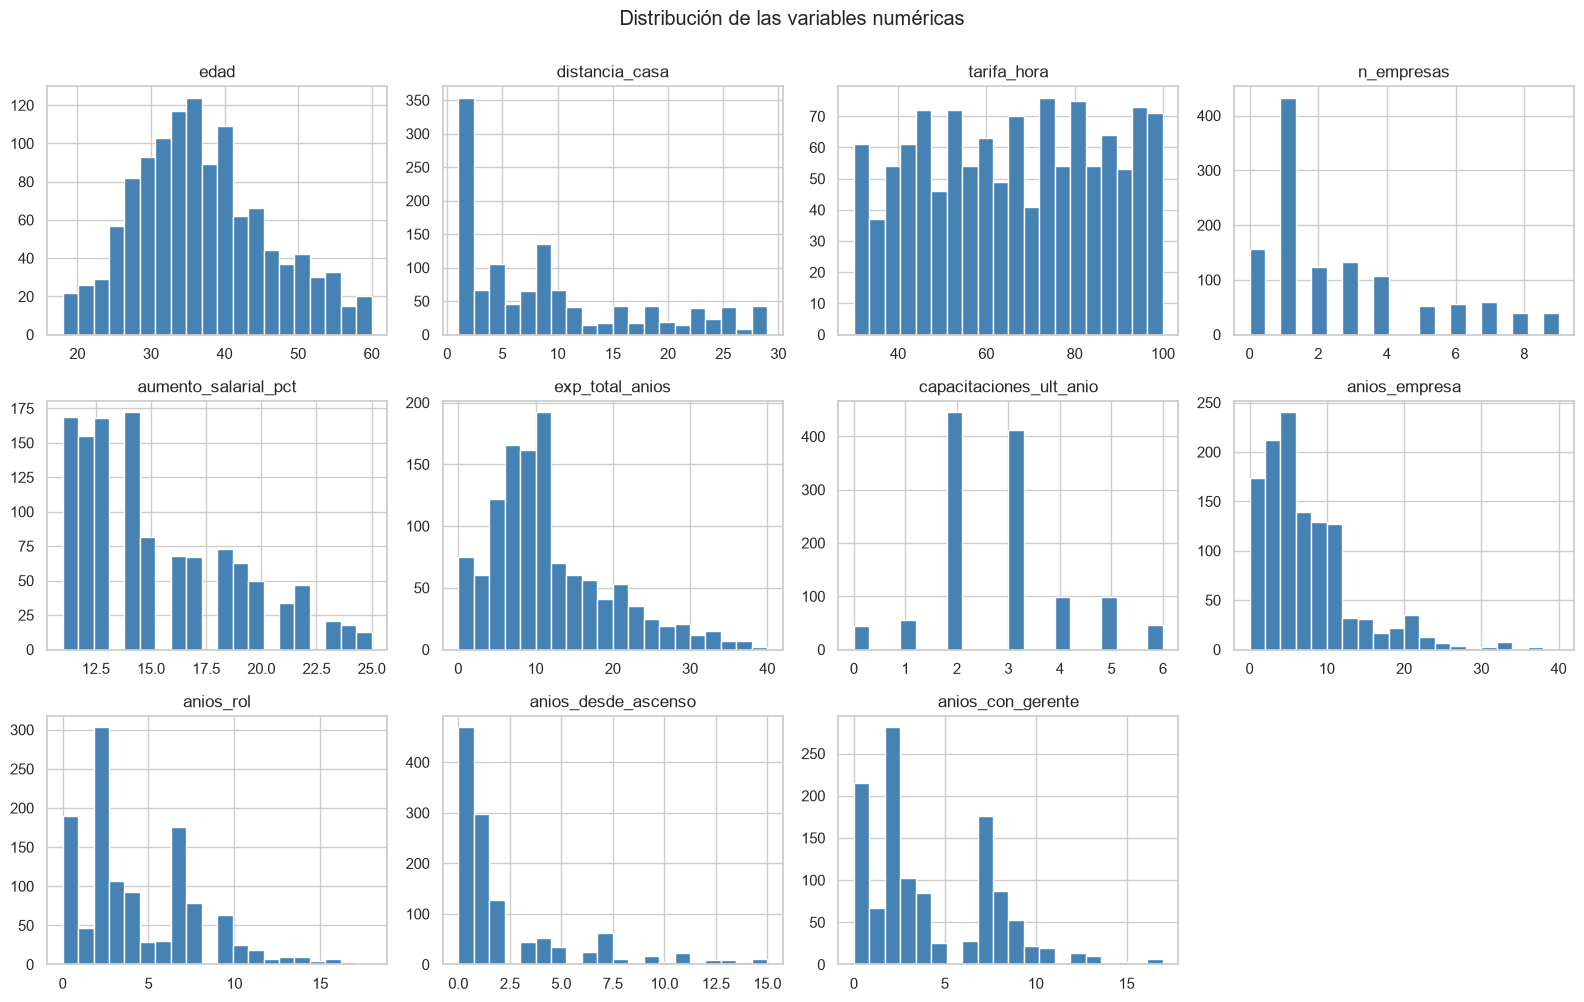

In [8]:
datos[numericas_rrhh].hist(bins=20, figsize=(16, 10), layout=(3, 4), color="steelblue", edgecolor="white")
plt.suptitle("Distribución de las variables numéricas", y=1.0)
plt.tight_layout()
plt.show()

In [9]:
def resumen_numerico(tabla):
    q1, q3 = tabla.quantile(0.25), tabla.quantile(0.75)
    iqr = q3 - q1
    atipicos = ((tabla < q1 - 1.5 * iqr) | (tabla > q3 + 1.5 * iqr)).sum()
    return pd.DataFrame({
        "Media": tabla.mean(), "Mediana": tabla.median(), "Desv. estándar": tabla.std(),
        "Mín": tabla.min(), "Máx": tabla.max(), "Asimetría": tabla.skew(),
        "Atípicos (IQR)": atipicos, "% atípicos": atipicos / len(tabla) * 100,
    }).round(2)


resumen_numerico(datos[numericas_rrhh])

,Media,Mediana,Desv. estándar,Mín,Máx,Asimetría,Atípicos (IQR),% atípicos
edad,36.92,36.0,9.09,18,60,0.38,0,0.00
distancia_casa,9.17,7.0,8.18,1,29,0.96,0,0.00
tarifa_hora,65.98,66.0,20.21,30,100,-0.04,0,0.00
n_empresas,2.66,2.0,2.47,0,9,1.05,39,3.25
aumento_salarial_pct,15.22,14.0,3.63,11,25,0.81,0,0.00
exp_total_anios,11.33,10.0,7.80,0,40,1.09,51,4.25
capacitaciones_ult_anio,2.79,3.0,1.26,0,6,0.53,188,15.67
anios_empresa,7.08,5.0,6.24,0,40,1.79,56,4.67
anios_rol,4.29,3.0,3.61,0,18,0.89,16,1.33
anios_desde_ascenso,2.19,1.0,3.22,0,15,1.97,88,7.33


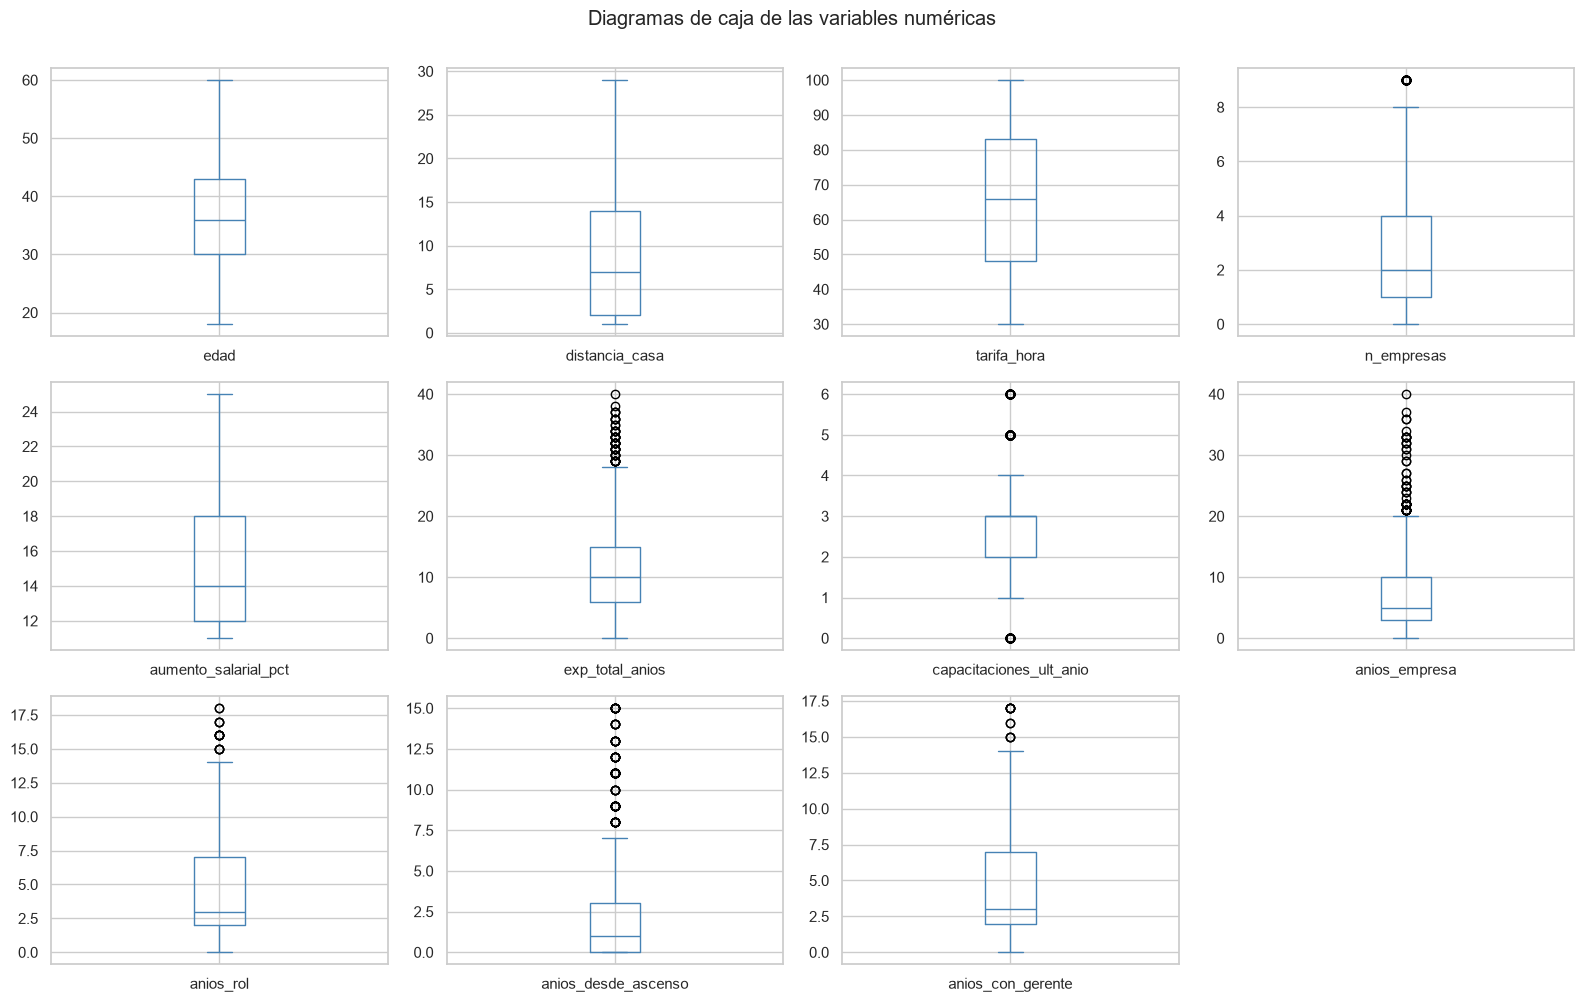

In [10]:
datos[numericas_rrhh].plot(kind="box", subplots=True, layout=(3, 4), figsize=(16, 10), sharey=False, color="steelblue")
plt.suptitle("Diagramas de caja de las variables numéricas", y=1.0)
plt.tight_layout()
plt.show()

**Interpretación:**

- **Edad** (18 a 60 años, media de 37) y **tarifa por hora** son casi simétricas y no tienen atípicos.
- Las variables de **años** (experiencia total, en la empresa, en el puesto, sin ascenso) tienen **asimetría positiva**: la mayoría de los empleados tiene pocos años y unos pocos tienen muchos. Por ejemplo, la mediana de años en la empresa es 5, pero el máximo es 40.
- `anios_desde_ascenso` es la más asimétrica (1.97): la mitad de los empleados tuvo un ascenso hace 1 año o menos.
- `capacitaciones_ult_anio` tiene 15.7% de atípicos, pero no son errores. La mayoría de los empleados (72%) tiene 2 o 3 capacitaciones, y la regla del rango intercuartílico (IQR) marca como atípicos los valores 0, 5 y 6, que son perfectamente posibles.
- **Decisión:** los atípicos son valores plausibles (personas con carreras largas), así que **no se eliminan**. Como K-medias es sensible a los valores extremos, las variables se escalarán y se puede considerar una transformación logarítmica para las de años.

### 6.2 Escalas ordinales y calificación de desempeño

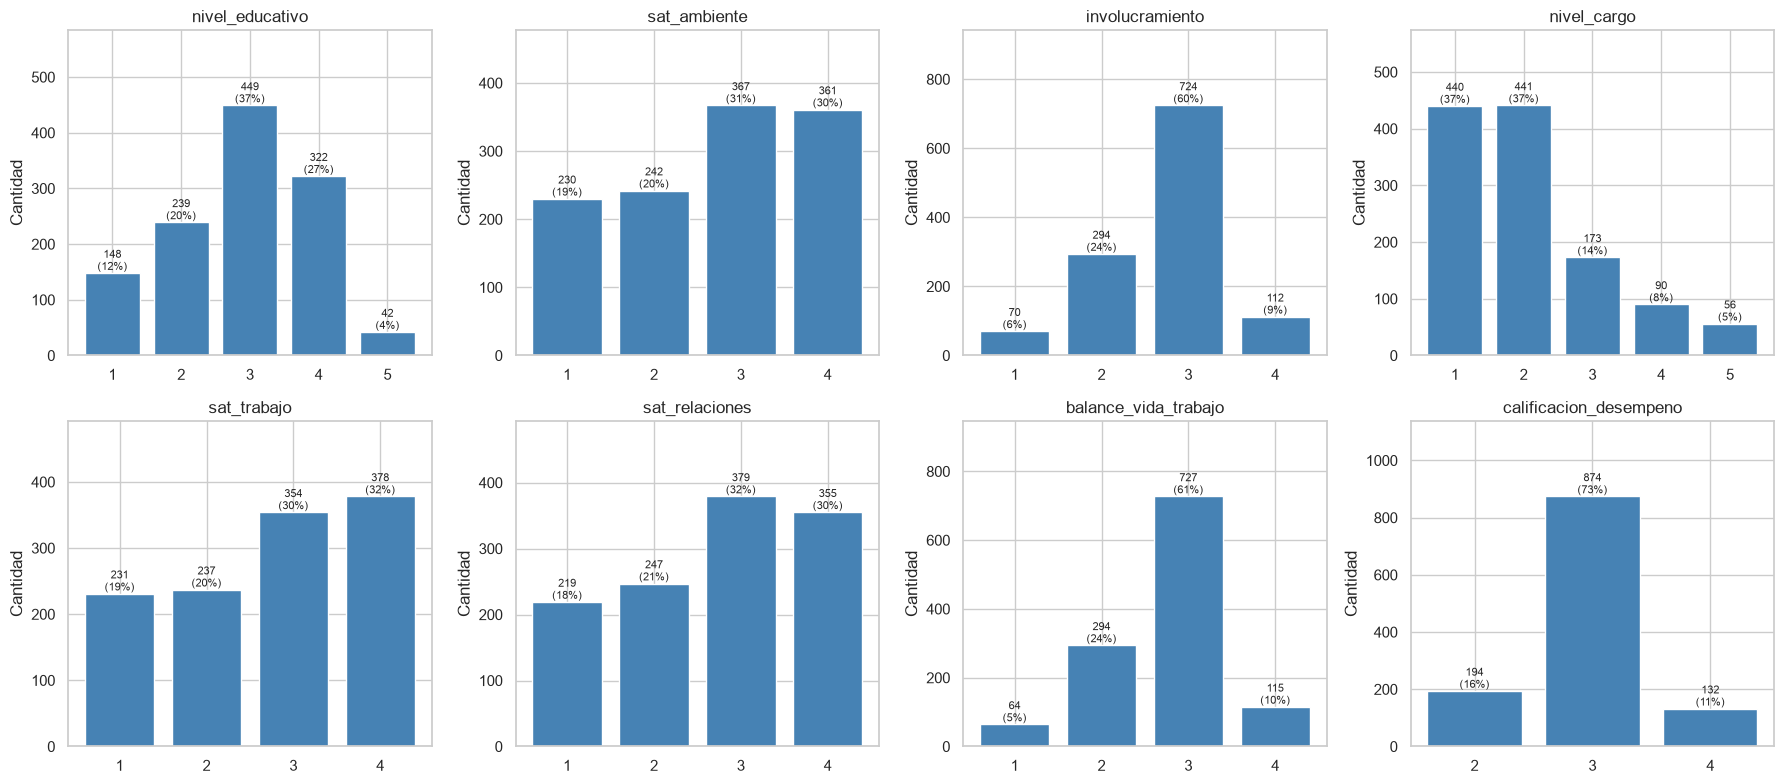

In [11]:
def barras_con_porcentaje(serie, titulo, ax, orden=None):
    conteo = serie.value_counts()
    conteo = conteo.reindex(orden, fill_value=0) if orden is not None else conteo.sort_index()
    ax.bar(conteo.index.astype(str), conteo.values, color="steelblue")
    total = conteo.sum()
    for i, valor in enumerate(conteo.values):
        ax.text(i, valor, f"{valor}\n({valor / total:.0%})", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, conteo.max() * 1.3)
    ax.set_title(titulo)
    ax.set_ylabel("Cantidad")


fig, ejes = plt.subplots(2, 4, figsize=(18, 8))
for ax, columna in zip(ejes.flat, ordinales):
    barras_con_porcentaje(datos[columna], columna, ax)
plt.tight_layout()
plt.show()

**Interpretación:**

- Las tres escalas de **satisfacción** (ambiente, puesto y relaciones) tienen una forma muy parecida: cerca del 60% responde 3 o 4 y cerca del 40% responde 1 o 2.
- **Involucramiento** y **equilibrio vida-trabajo** se concentran en el valor 3 (60% y 61%).
- El **nivel del puesto** tiene forma de pirámide: 73% está en los niveles 1 y 2 y solo 5% en el nivel 5.
- El **nivel educativo** más común es 3 (37%).
- **`calificacion_desempeno`** está muy concentrada: **73%** tiene calificación 3, 16% tiene 2 y 11% tiene 4. Este desbalance es importante si se quiere predecir el desempeño.

### 6.3 Variables categóricas

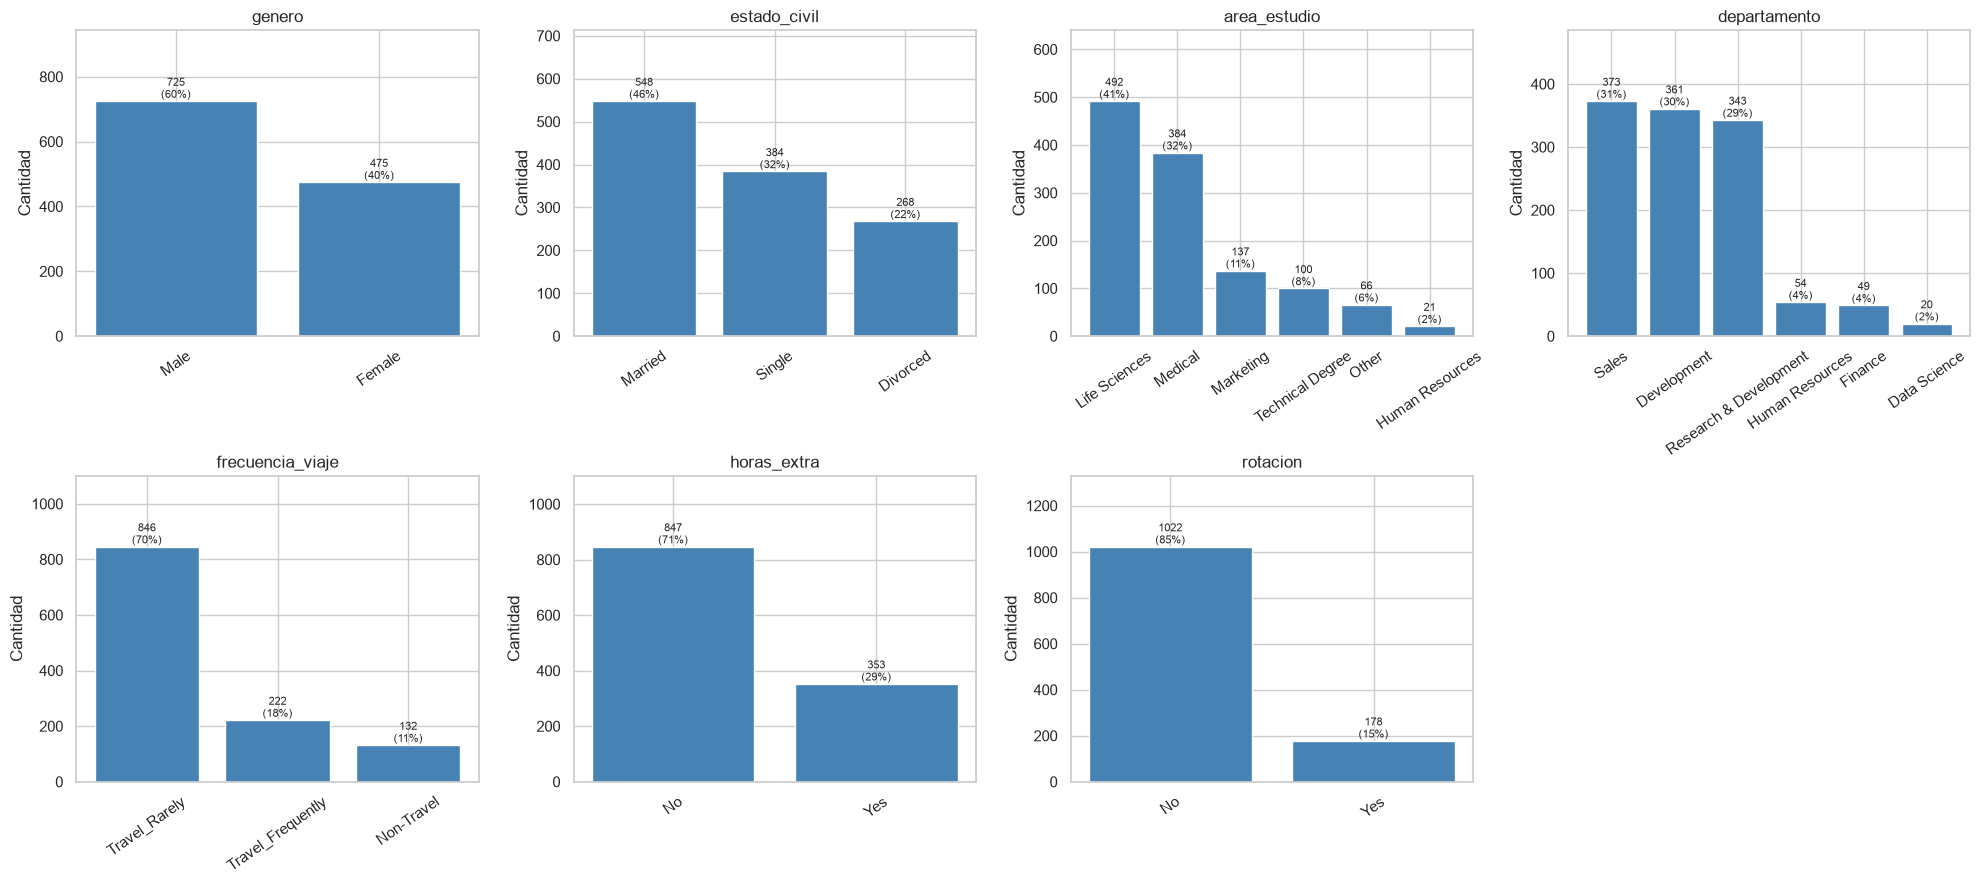

In [12]:
fig, ejes = plt.subplots(2, 4, figsize=(20, 9))
for ax, columna in zip(ejes.flat, nominales):
    conteo = datos[columna].value_counts()
    barras_con_porcentaje(datos[columna], columna, ax, orden=conteo.index)
    ax.tick_params(axis="x", rotation=35)
ejes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

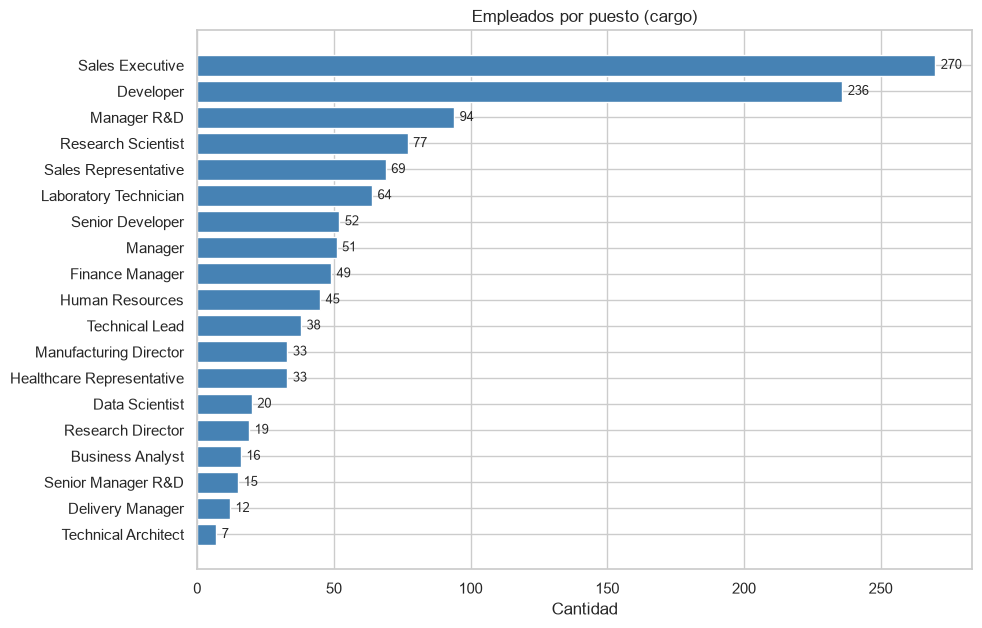

In [13]:
puestos = datos["cargo"].value_counts().sort_values()
plt.figure(figsize=(10, 7))
plt.barh(puestos.index, puestos.values, color="steelblue")
for i, valor in enumerate(puestos.values):
    plt.text(valor + 2, i, str(valor), va="center", fontsize=9)
plt.title("Empleados por puesto (cargo)")
plt.xlabel("Cantidad")
plt.show()

**Interpretación:**

- **Género:** 60% hombres y 40% mujeres. **Estado civil:** predominan las personas casadas (46%).
- **Formación:** Life Sciences (41%) y Medical (32%) suman casi tres cuartas partes; solo el 11% viene de Marketing.
- **Departamento:** Sales (31%), Development (30%) y Research & Development (29%) concentran el 90% de los empleados; Human Resources, Finance y Data Science son áreas pequeñas.
- **Puesto:** Sales Executive (270) y Developer (236) son los más comunes. Hay 19 puestos y varios tienen menos de 20 personas.
- **Viajes y horas extra:** el 70% viaja rara vez y el 29% hace horas extra.
- **Rotación:** el 15% de los empleados dejó la empresa (178 personas).
- **Observación:** la empresa no es solo de ventas. Los **agentes de ventas** (Sales Executive y Sales Representative) son 339 personas, el 28% del total.

### 6.4 Correlación entre las variables de RR. HH.

Se usa la correlación de **Spearman**, adecuada para mezclar variables numéricas y ordinales.

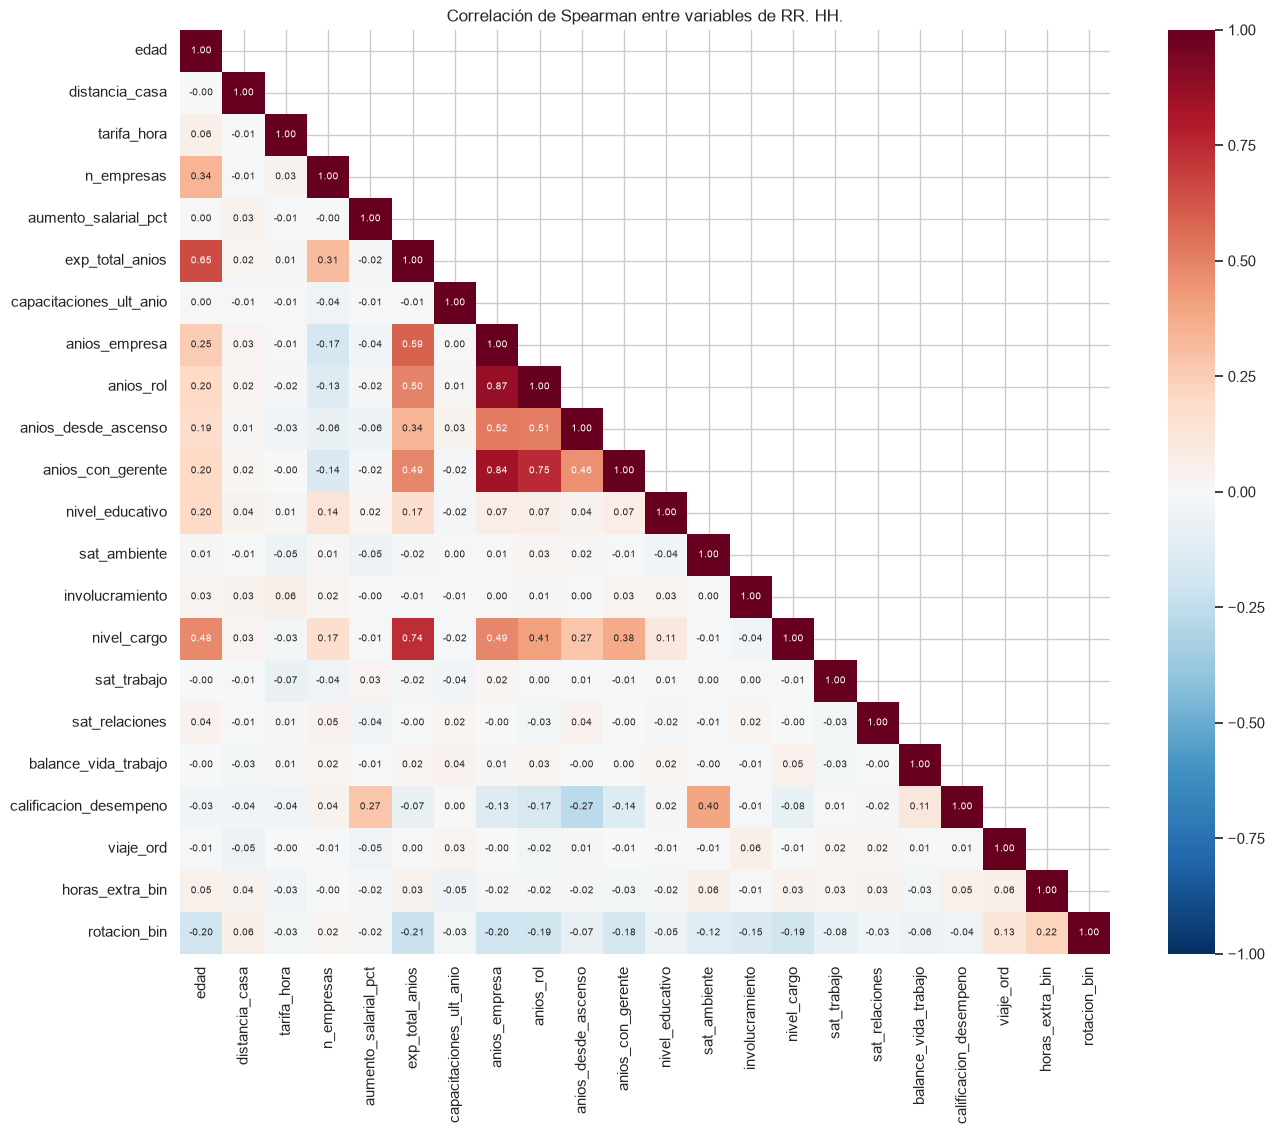

In [14]:
variables_rrhh = numericas_rrhh + ordinales + ["viaje_ord", "horas_extra_bin", "rotacion_bin"]
correlacion_rrhh = datos[variables_rrhh].corr(method="spearman")
mascara = np.triu(np.ones_like(correlacion_rrhh, dtype=bool), k=1)
plt.figure(figsize=(15, 12))
sns.heatmap(correlacion_rrhh, mask=mascara, annot=True, fmt=".2f", annot_kws={"size": 7},
            cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlación de Spearman entre variables de RR. HH.")
plt.show()

In [15]:
pares = correlacion_rrhh.where(~mascara & ~np.eye(len(correlacion_rrhh), dtype=bool)).stack()
pares.abs().sort_values(ascending=False).head(10).round(2).to_frame("|r| de Spearman")

|r| de Spearman
anios_rol           anios_empresa               0.87
anios_con_gerente   anios_empresa               0.84
                    anios_rol                   0.75
nivel_cargo         exp_total_anios             0.74
exp_total_anios     edad                        0.65
anios_empresa       exp_total_anios             0.59
anios_desde_ascenso anios_empresa               0.52
                    anios_rol                   0.51
anios_rol           exp_total_anios             0.50
anios_con_gerente   exp_total_anios             0.49

**Interpretación:**

- Las correlaciones más fuertes están en el bloque de **antigüedad**: años en la empresa, en el puesto actual y con el jefe actual (de 0.75 a 0.87). Las tres miden casi lo mismo: cuánto tiempo lleva la persona en su posición.
- El **nivel del puesto** y la **experiencia total** también están muy relacionados (0.74), igual que la **edad** y la **experiencia** (0.65).
- La satisfacción con el puesto y con las relaciones, la distancia al trabajo y la tarifa por hora casi no se relacionan con el resto. La satisfacción con el ambiente es la excepción: se relaciona con el desempeño (sección 6.5).
- **Implicación para K-medias:** si se usan todas las variables de antigüedad, ese bloque pesará varias veces en la distancia. Conviene quedarse con una o dos (por ejemplo, `exp_total_anios` y `anios_empresa`) o resumirlas con componentes principales (PCA).

### 6.5 ¿Qué se relaciona con el desempeño (`calificacion_desempeno`)?

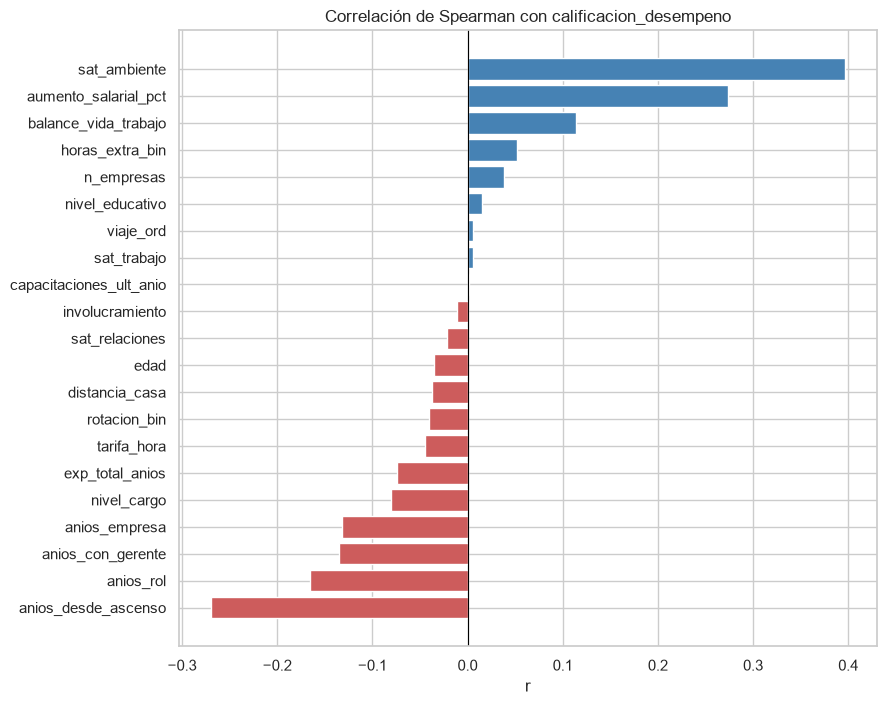

In [16]:
correlacion_desempeno = correlacion_rrhh["calificacion_desempeno"].drop("calificacion_desempeno").sort_values()
colores = ["indianred" if valor < 0 else "steelblue" for valor in correlacion_desempeno]
plt.figure(figsize=(9, 8))
plt.barh(correlacion_desempeno.index, correlacion_desempeno.values, color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlación de Spearman con calificacion_desempeno")
plt.xlabel("r")
plt.show()

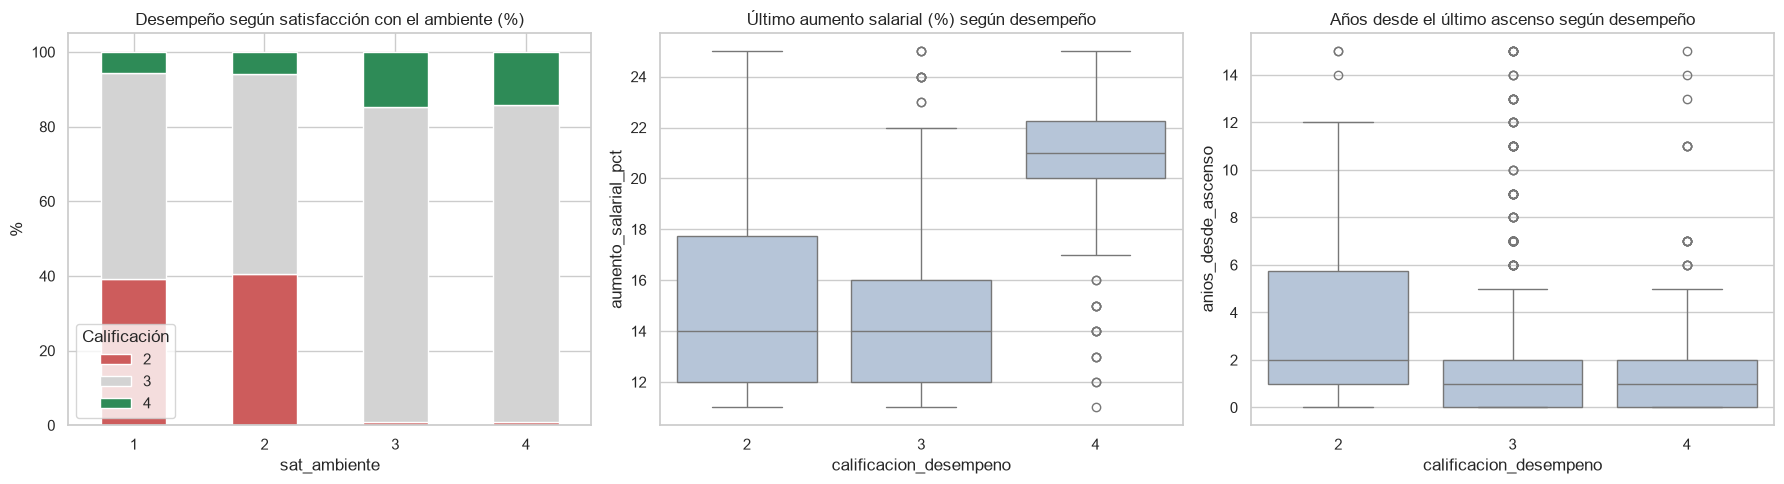

In [17]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
tabla = pd.crosstab(datos["sat_ambiente"], datos["calificacion_desempeno"], normalize="index") * 100
tabla.plot(kind="bar", stacked=True, ax=ejes[0], rot=0, color=["indianred", "lightgray", "seagreen"])
ejes[0].set_title("Desempeño según satisfacción con el ambiente (%)")
ejes[0].set_ylabel("%")
ejes[0].legend(title="Calificación")

sns.boxplot(data=datos, x="calificacion_desempeno", y="aumento_salarial_pct", ax=ejes[1], color="lightsteelblue")
ejes[1].set_title("Último aumento salarial (%) según desempeño")
sns.boxplot(data=datos, x="calificacion_desempeno", y="anios_desde_ascenso", ax=ejes[2], color="lightsteelblue")
ejes[2].set_title("Años desde el último ascenso según desempeño")
plt.tight_layout()
plt.show()

In [18]:
desempeno_departamento = pd.crosstab(datos["departamento"], datos["calificacion_desempeno"], normalize="index") * 100
desempeno_departamento["Promedio"] = datos.groupby("departamento")["calificacion_desempeno"].mean()
desempeno_departamento.round(2).sort_values("Promedio", ascending=False)

calificacion_desempeno,2,3,4,Promedio
departamento,,,,
Development,3.60,84.21,12.19,3.09
Data Science,5.00,85.00,10.00,3.05
Human Resources,18.52,70.37,11.11,2.93
Research & Development,19.83,68.22,11.95,2.92
Sales,23.32,67.29,9.38,2.86
Finance,30.61,61.22,8.16,2.78


**Interpretación:**

- Las variables más relacionadas con el desempeño son la **satisfacción con el ambiente laboral (r = 0.40)**, el **último aumento salarial (0.27)** y los **años desde el último ascenso (−0.27)**.
- La satisfacción con el ambiente marca una frontera clara: con satisfacción 1 o 2, cerca del **40%** tiene desempeño bajo (2); con satisfacción 3 o 4, solo el **1%**.
- Los empleados con desempeño 4 recibieron aumentos mucho mayores (mediana de **21%**, frente a 14% en los demás). Es probable que el aumento sea **consecuencia** de la calificación y no su causa.
- Los empleados con desempeño 2 llevan más tiempo sin ascender (mediana de 2 años, frente a 1).
- Por departamento, **Development** y **Data Science** tienen el mejor desempeño promedio (3.09 y 3.05), y **Sales** y **Finance** el más bajo (2.86 y 2.78). En Sales, el 23% tiene desempeño 2.

### 6.6 Rotación de personal (`rotacion`)

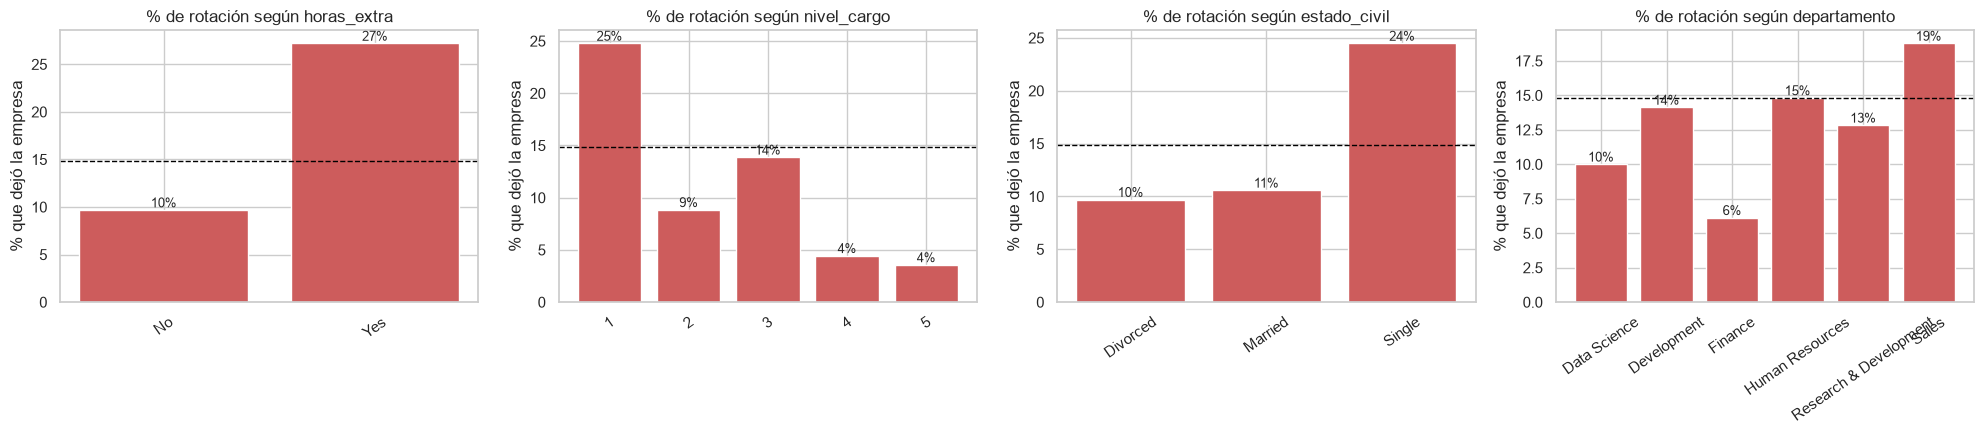

Tasa general de rotación: 14.8%


In [19]:
fig, ejes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, columna in zip(ejes, ["horas_extra", "nivel_cargo", "estado_civil", "departamento"]):
    tasa = datos.groupby(columna)["rotacion_bin"].mean() * 100
    ax.bar(tasa.index.astype(str), tasa.values, color="indianred")
    for i, valor in enumerate(tasa.values):
        ax.text(i, valor, f"{valor:.0f}%", ha="center", va="bottom", fontsize=9)
    ax.axhline(datos["rotacion_bin"].mean() * 100, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"% de rotación según {columna}")
    ax.set_ylabel("% que dejó la empresa")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()
print(f"Tasa general de rotación: {datos['rotacion_bin'].mean():.1%}")

**Interpretación** (la línea punteada es la tasa general):

- La tasa general de rotación es **14.8%**.
- Quienes hacen **horas extra** se van casi tres veces más (27% frente a 10%).
- La rotación es mayor en el **nivel 1** (25%) y baja mucho en los niveles 4 y 5 (menos del 5%).
- Las personas **solteras** se van más (24%) que las casadas o divorciadas (cerca del 10%).
- **Sales** es el departamento con más rotación (19%).

### 6.7 Validación de las métricas comerciales

El nombre del archivo original (*Imputed_Distribution*) indica que algunos valores fueron **imputados a partir de una distribución**. La limpieza conservó estas 12 métricas, así que antes de usarlas hay que comprobar si contienen información real. Si fueran datos reales, se esperaría que:

- se relacionen entre sí (por ejemplo, más contactos o mejor conversión → más ventas);
- se relacionen con el puesto (el salario debería subir con el nivel jerárquico);
- sean distintas en el departamento de ventas que en los demás;
- se relacionen con la calificación de desempeño.

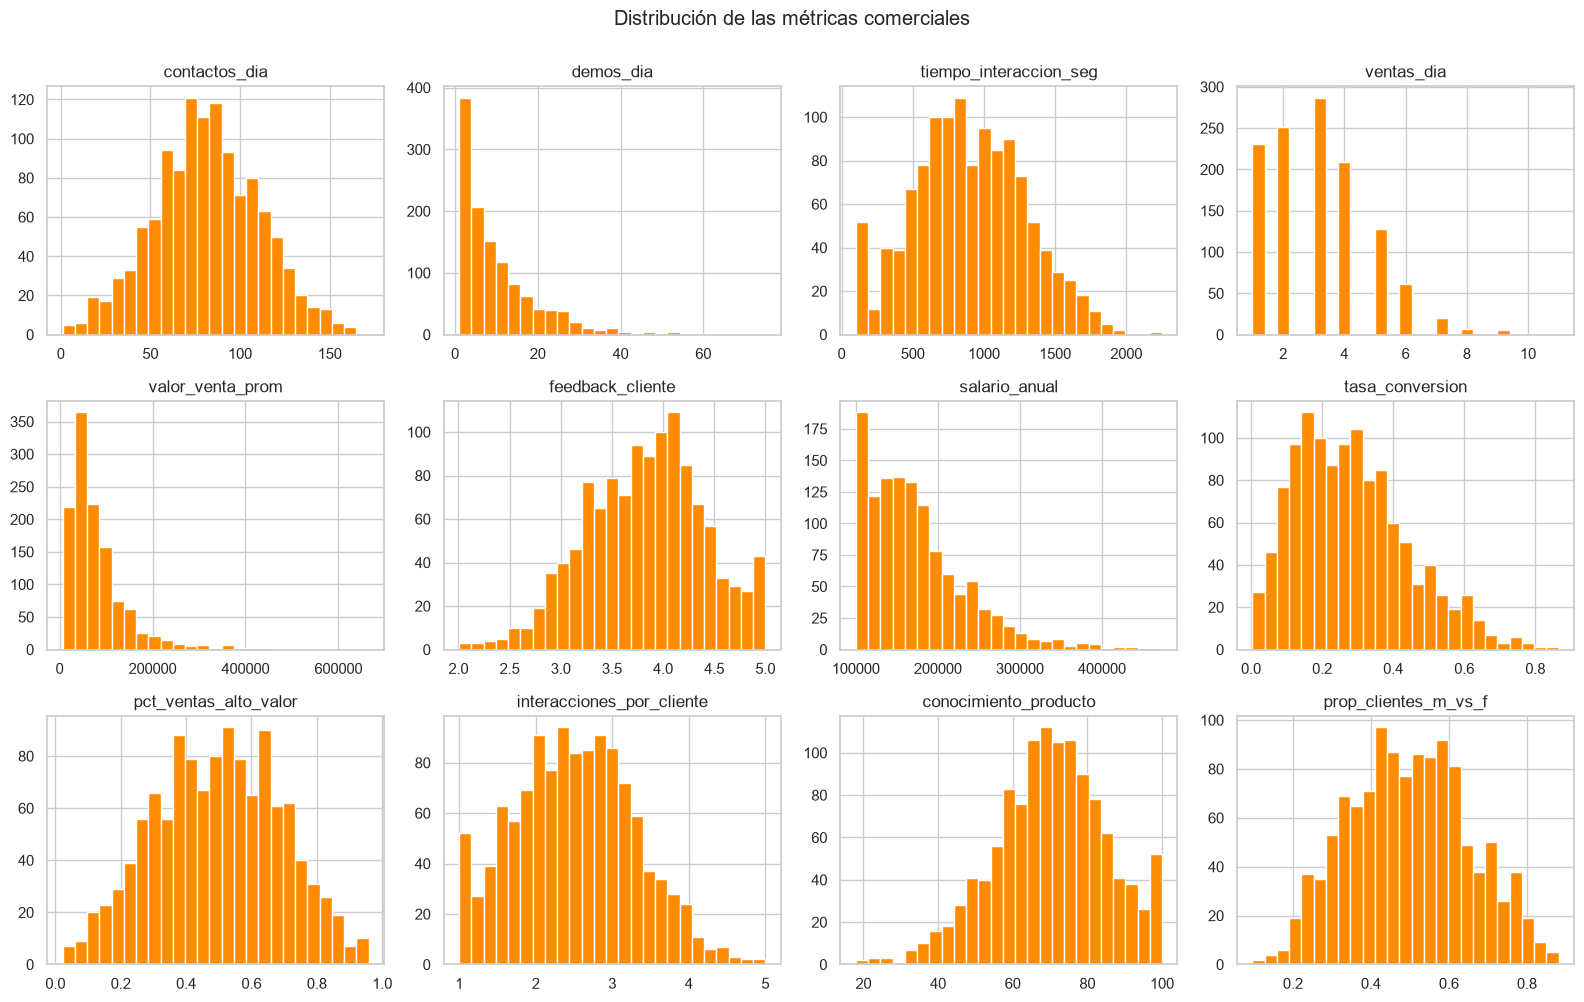

,Media,Mediana,Desv. estándar,Mín,Máx,Asimetría,Atípicos (IQR),% atípicos
contactos_dia,81.38,81.42,29.67,1.00,171.77,0.04,1,0.08
demos_dia,10.21,7.10,10.10,1.00,75.00,1.94,51,4.25
tiempo_interaccion_seg,898.71,877.57,390.55,100.00,2251.17,0.11,1,0.08
ventas_dia,3.07,3.00,1.63,1.00,11.00,0.74,13,1.08
valor_venta_prom,80787.74,60499.89,66695.89,6309.89,665196.14,2.64,72,6.00
feedback_cliente,3.82,3.85,0.58,2.01,5.00,-0.17,4,0.33
salario_anual,173403.23,160467.50,61183.69,100000.00,473278.00,1.30,40,3.33
tasa_conversion,0.28,0.27,0.16,0.00,0.87,0.66,12,1.00
pct_ventas_alto_valor,0.49,0.50,0.19,0.02,0.96,-0.03,0,0.00
interacciones_por_cliente,2.51,2.49,0.79,1.00,5.00,0.17,4,0.33


In [20]:
datos[comerciales].hist(bins=25, figsize=(16, 10), layout=(3, 4), color="darkorange", edgecolor="white")
plt.suptitle("Distribución de las métricas comerciales", y=1.0)
plt.tight_layout()
plt.show()
resumen_numerico(datos[comerciales])

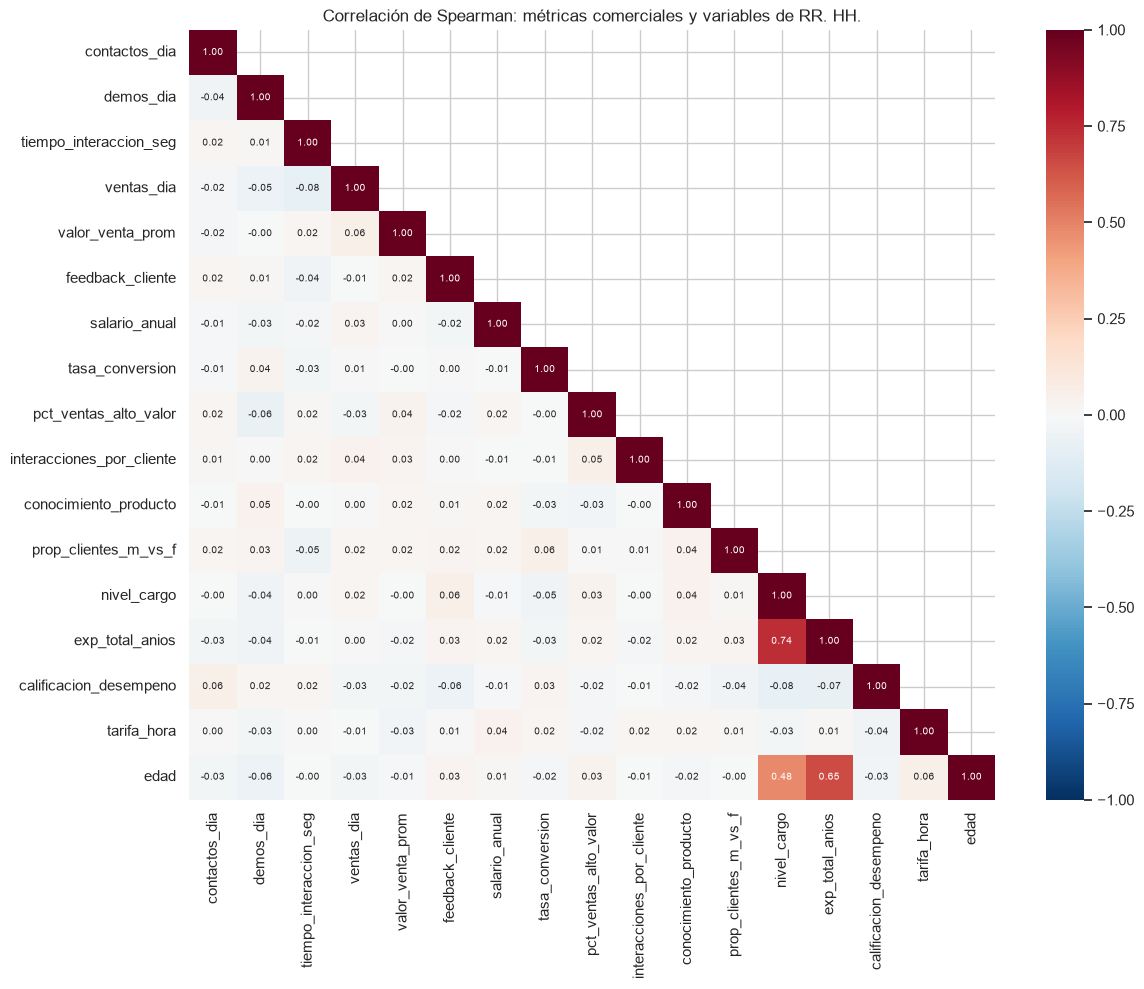

In [21]:
variables_contraste = ["nivel_cargo", "exp_total_anios", "calificacion_desempeno", "tarifa_hora", "edad"]
correlacion_comercial = datos[comerciales + variables_contraste].corr(method="spearman")
mascara = np.triu(np.ones_like(correlacion_comercial, dtype=bool), k=1)
plt.figure(figsize=(13, 10))
sns.heatmap(correlacion_comercial, mask=mascara, annot=True, fmt=".2f", annot_kws={"size": 7},
            cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlación de Spearman: métricas comerciales y variables de RR. HH.")
plt.show()

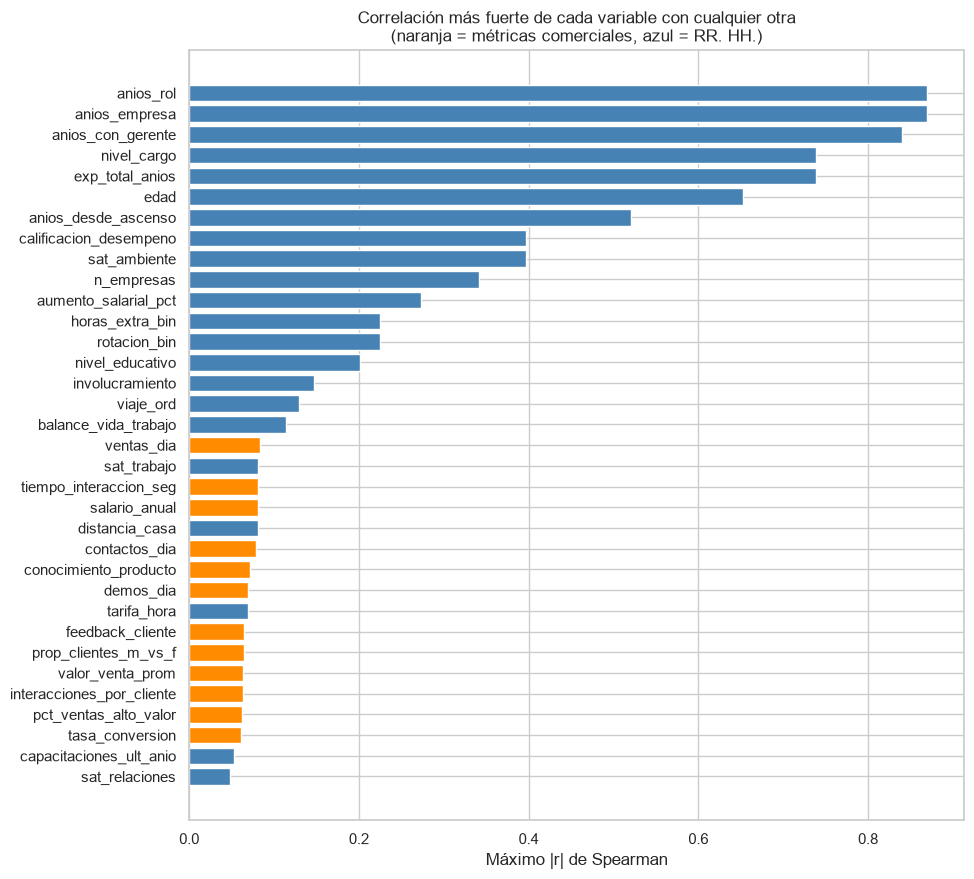

In [22]:
todas = numericas_rrhh + ordinales + ["viaje_ord", "horas_extra_bin", "rotacion_bin"] + comerciales
correlacion_absoluta = datos[todas].corr(method="spearman").abs()
correlacion_absoluta = correlacion_absoluta.mask(np.eye(len(todas), dtype=bool))
max_correlacion = correlacion_absoluta.max().sort_values()

colores = ["darkorange" if v in comerciales else "steelblue" for v in max_correlacion.index]
plt.figure(figsize=(10, 10))
plt.barh(max_correlacion.index, max_correlacion.values, color=colores)
plt.title("Correlación más fuerte de cada variable con cualquier otra\n(naranja = métricas comerciales, azul = RR. HH.)")
plt.xlabel("Máximo |r| de Spearman")
plt.show()

La prueba de **Kruskal-Wallis** compara si una variable tiene la misma distribución en varios grupos (no supone normalidad). Un p-valor menor a 0.05 indica que hay diferencias entre los grupos. Como se hacen 36 pruebas, se espera que unas 2 den p < 0.05 solo por azar; por eso también se aplica la **corrección de Bonferroni**, que divide el umbral 0.05 entre la cantidad de pruebas.

In [23]:
def p_kruskal(columna, grupo):
    muestras = [g[columna].to_numpy() for _, g in datos.groupby(grupo)]
    return stats.kruskal(*muestras).pvalue


pruebas = pd.DataFrame({
    "p-valor por departamento": [p_kruskal(c, "departamento") for c in comerciales],
    "p-valor por desempeño": [p_kruskal(c, "calificacion_desempeno") for c in comerciales],
    "p-valor por nivel del puesto": [p_kruskal(c, "nivel_cargo") for c in comerciales],
}, index=comerciales)

n_pruebas = pruebas.size
print(f"Pruebas realizadas: {n_pruebas} | con p < 0.05: {(pruebas < 0.05).sum().sum()} | "
      f"esperables solo por azar: {n_pruebas * 0.05:.1f}")
print(f"Con corrección de Bonferroni (p < {0.05 / n_pruebas:.4f}): {(pruebas < 0.05 / n_pruebas).sum().sum()}")
pruebas["¿Alguna p < 0.05?"] = (pruebas < 0.05).any(axis=1).map({True: "Sí", False: "No"})
pruebas.round(3)

Pruebas realizadas: 36 | con p < 0.05: 5 | esperables solo por azar: 1.8
Con corrección de Bonferroni (p < 0.0014): 1


,p-valor por departamento,p-valor por desempeño,p-valor por nivel del puesto,¿Alguna p < 0.05?
contactos_dia,0.064,0.136,0.024,Sí
demos_dia,0.087,0.809,0.316,No
tiempo_interaccion_seg,0.524,0.515,0.884,No
ventas_dia,0.449,0.410,0.206,No
valor_venta_prom,0.527,0.345,0.834,No
feedback_cliente,0.260,0.016,0.105,Sí
salario_anual,0.396,0.896,0.235,No
tasa_conversion,0.732,0.242,0.280,No
pct_ventas_alto_valor,0.364,0.732,0.001,Sí
interacciones_por_cliente,0.550,0.983,0.966,No


In [24]:
contraste = pd.Series({
    "aumento_salarial_pct por desempeño": p_kruskal("aumento_salarial_pct", "calificacion_desempeno"),
    "sat_ambiente por desempeño": p_kruskal("sat_ambiente", "calificacion_desempeno"),
    "exp_total_anios por nivel del puesto": p_kruskal("exp_total_anios", "nivel_cargo"),
}, name="p-valor (Kruskal-Wallis)")
contraste.apply(lambda p: f"{p:.2e}").to_frame()

,p-valor (Kruskal-Wallis)
aumento_salarial_pct por desempeño,6.96e-52
sat_ambiente por desempeño,1.95e-54
exp_total_anios por nivel del puesto,1.43e-143


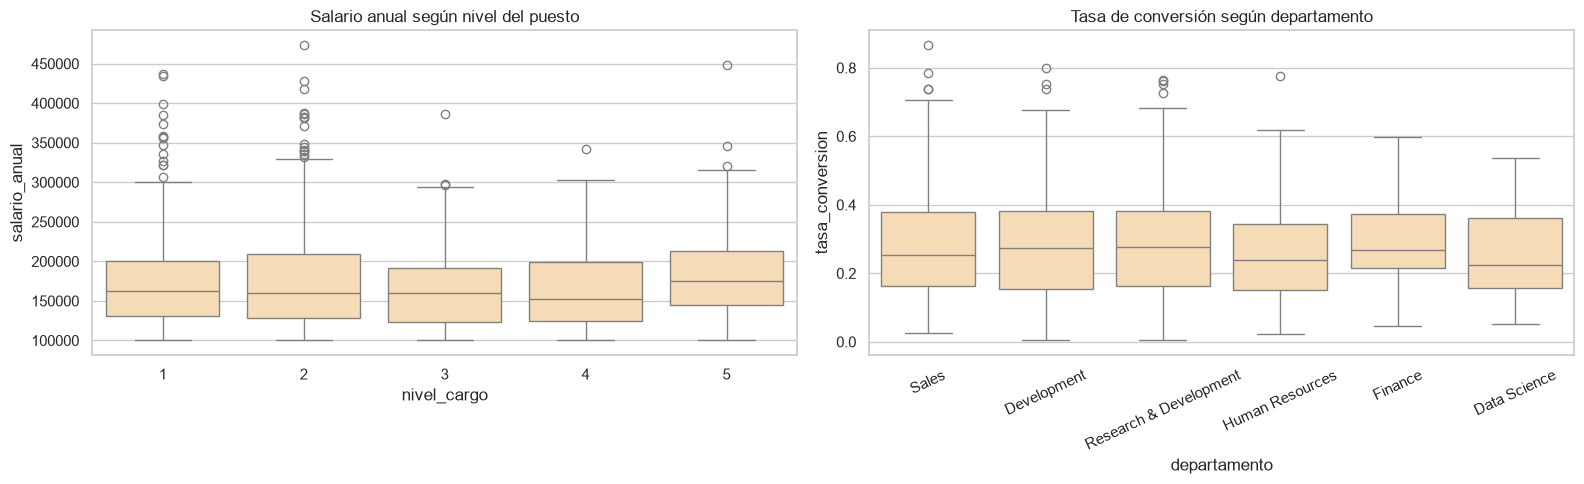

In [25]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=datos, x="nivel_cargo", y="salario_anual", ax=ejes[0], color="navajowhite")
ejes[0].set_title("Salario anual según nivel del puesto")
orden_departamentos = datos["departamento"].value_counts().index
sns.boxplot(data=datos, x="departamento", y="tasa_conversion", order=orden_departamentos, ax=ejes[1], color="navajowhite")
ejes[1].set_title("Tasa de conversión según departamento")
ejes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

**Interpretación:** las cuatro comprobaciones llevan a la misma conclusión: **las métricas comerciales prácticamente no se relacionan con nada.**

- **Entre sí y con el resto:** ninguna métrica comercial tiene una correlación mayor a 0.09 con otra variable. En datos reales esto no tiene sentido: más contactos o una mejor conversión deberían traducirse en más ventas.
- **Con el puesto:** el **salario anual no sube con el nivel del puesto**: las medianas van de unos 152 000 a 175 000, sin una tendencia clara, y la diferencia no es significativa (p = 0.24). En cambio, la experiencia sí crece con el nivel (p ≈ 10⁻¹⁴³).
- **Por departamento:** la tasa de conversión de Sales no se diferencia de la de Development, Finance o Data Science (p = 0.73), áreas que normalmente no venden.
- **Con el desempeño:** entre las calificaciones 2, 3 y 4, solo `feedback_cliente` da p < 0.05, y no resiste la corrección de Bonferroni. En cambio, el aumento salarial y la satisfacción con el ambiente sí distinguen las calificaciones, con p-valores de 10⁻⁵² o menores.
- De las 36 pruebas, 5 dan p < 0.05, cuando por azar se esperarían unas 2. Sin embargo, solo 1 resiste la corrección de Bonferroni (`pct_ventas_alto_valor` por nivel del puesto), y esa diferencia no sigue un orden lógico: los promedios suben y bajan entre niveles (el nivel 4 tiene el valor más alto y el nivel 5 el más bajo).

En el gráfico de correlación máxima, algunas variables de RR. HH. también tienen correlaciones bajas (distancia al trabajo, tarifa por hora, capacitaciones). En su caso es esperable, porque son atributos que no tienen por qué depender de los demás. Las métricas comerciales, en cambio, **deberían** estar relacionadas por definición, y no lo están.

**Conclusión:** todo indica que estas 12 columnas fueron **generadas o imputadas de forma independiente** a partir de una distribución (de ahí el nombre *Imputed_Distribution*), sin relación con cada empleado. Usarlas en K-medias produciría grupos artificiales, muy difíciles de justificar.

### 6.8 Enfoque en los agentes de ventas

El objetivo planteado por el grupo se centra en los **agentes de ventas**, identificados en la limpieza con `es_agente_ventas` (puestos *Sales Executive* y *Sales Representative*).

In [26]:
print(f"Agentes de ventas: {datos['es_agente_ventas'].sum()} de {len(datos)} empleados "
      f"({datos['es_agente_ventas'].mean():.1%})")

comparacion = datos.groupby(datos["es_agente_ventas"].map({1: "Agentes de ventas", 0: "Resto"}))[
    comerciales + ["calificacion_desempeno", "rotacion_bin"]].mean().T.round(2)
comparacion["Diferencia %"] = ((comparacion["Agentes de ventas"] / comparacion["Resto"] - 1) * 100).round(1)
comparacion

Agentes de ventas: 339 de 1200 empleados (28.2%)


es_agente_ventas,Agentes de ventas,Resto,Diferencia %
contactos_dia,78.73,82.42,-4.5
demos_dia,10.12,10.25,-1.3
tiempo_interaccion_seg,885.74,903.82,-2.0
ventas_dia,3.03,3.09,-1.9
valor_venta_prom,82879.64,79964.10,3.6
feedback_cliente,3.84,3.82,0.5
salario_anual,171455.52,174170.10,-1.6
tasa_conversion,0.28,0.28,0.0
pct_ventas_alto_valor,0.50,0.49,2.0
interacciones_por_cliente,2.50,2.52,-0.8


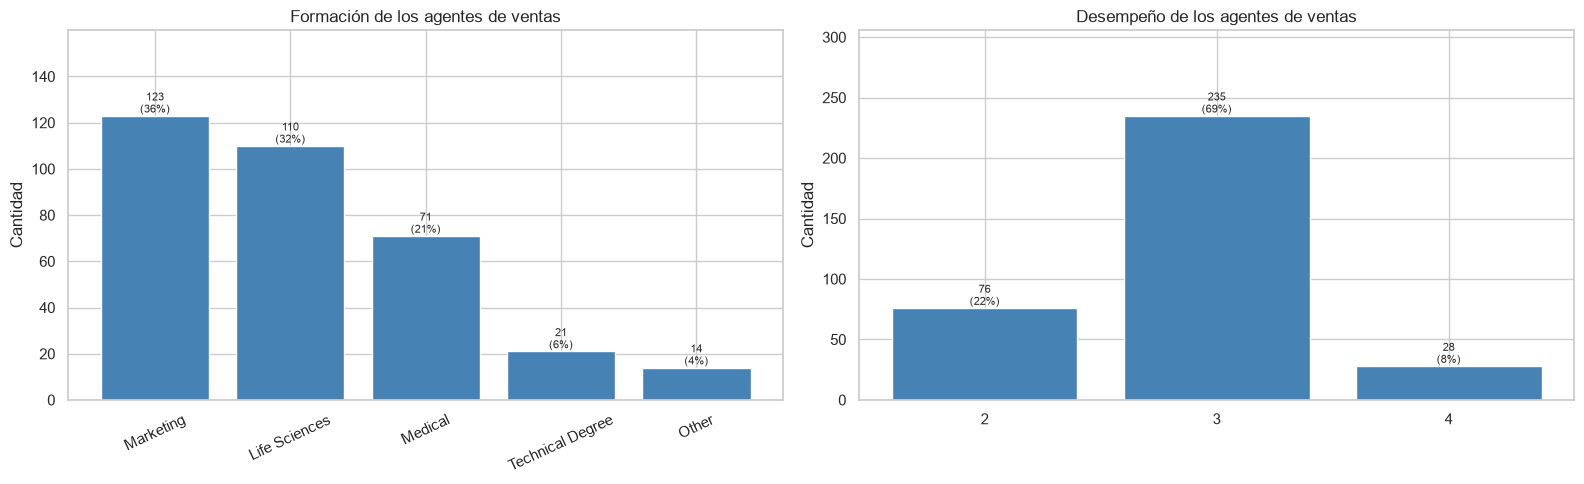

In [27]:
agentes = datos[datos["es_agente_ventas"] == 1]
fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
barras_con_porcentaje(agentes["area_estudio"], "Formación de los agentes de ventas", ejes[0],
                      orden=agentes["area_estudio"].value_counts().index)
ejes[0].tick_params(axis="x", rotation=25)
barras_con_porcentaje(agentes["calificacion_desempeno"], "Desempeño de los agentes de ventas", ejes[1])
plt.tight_layout()
plt.show()

**Interpretación:**

- Hay **339 agentes de ventas** (28% de los empleados).
- Sus métricas comerciales son **prácticamente iguales** a las del resto de la empresa: ninguna diferencia supera el 5%. Un desarrollador tiene, en promedio, prácticamente la misma tasa de conversión que un agente de ventas (0.29 y 0.28), lo que confirma que estas métricas no describen el trabajo real de cada persona.
- Los agentes de ventas tienen **peor desempeño promedio** (2.86 frente a 2.98) y **más rotación** (20% frente a 13%).
- Su formación más común es **Marketing (36%)**, seguida de Life Sciences (32%) y Medical (21%). En el resto de la empresa, Marketing es minoritario.
- En desempeño, el 22% de los agentes tiene calificación 2 y solo el 8% tiene 4.

## 7. Conclusiones del EDA

### Hallazgos principales

1. **Datos completos y coherentes:** 1200 empleados, sin nulos ni duplicados, con escalas dentro de rango y trayectorias lógicas. Los atípicos son valores plausibles y no se eliminan.
2. **Las variables de RR. HH. tienen estructura real:** antigüedad, experiencia, edad y nivel del puesto forman un bloque muy correlacionado (correlaciones de hasta 0.87).
3. **El desempeño se asocia sobre todo con la satisfacción con el ambiente laboral**, el último aumento salarial y el tiempo sin ascenso.
4. **La rotación (15%)** se concentra en quienes hacen horas extra, el nivel 1, las personas solteras y el departamento de ventas.
5. **Las 12 métricas comerciales no contienen información útil:** no se relacionan entre sí ni con el puesto, el departamento o el desempeño. Todo indica que fueron imputadas de forma independiente.
6. **Los agentes de ventas son solo el 28%** de los empleados. Tienen menor desempeño y mayor rotación que el resto, y vienen sobre todo de Marketing y Life Sciences.

### Implicaciones para la clusterización

| Decisión | Variables |
|---|---|
| **Usar** (escaladas) | `edad`, `exp_total_anios`, `anios_empresa`, `nivel_cargo`, `aumento_salarial_pct`, `anios_desde_ascenso`, `sat_ambiente`, `sat_trabajo`, `sat_relaciones`, `involucramiento`, `balance_vida_trabajo`, `horas_extra_bin`, `viaje_ord` |
| **Evaluar** (relación débil con el resto) | `distancia_casa`, `tarifa_hora`, `capacitaciones_ult_anio`, `nivel_educativo`, `n_empresas` |
| **Reducir** (redundantes) | `anios_rol` y `anios_con_gerente`, muy correlacionadas con los años en la empresa: se omiten o se resumen con PCA |
| **Solo para describir los grupos** | `calificacion_desempeno`, `rotacion`, `departamento`, `cargo`, `area_estudio`, `genero`, `estado_civil` y sus columnas codificadas, `es_ventas`, `es_agente_ventas` |
| **Excluir** | `emp_id` y las 12 métricas comerciales (se menciona como limitación del set) |

### Recomendación sobre el objetivo del grupo

El objetivo planteado (*segmentar a los agentes de ventas con mayor éxito según sus estadísticas*) depende de las métricas comerciales, y el EDA mostró que no son confiables. Una alternativa defendible es **segmentar a los empleados (o solo a los 339 agentes de ventas) según su perfil de RR. HH.** y después comparar el **desempeño**, la **rotación** y el **área de formación** de cada grupo. Así se conserva la idea original (qué caracteriza a quienes rinden mejor) usando variables que sí tienen información.

Para este segundo set, el enunciado permite usar otro algoritmo además de K-medias (por ejemplo, clusterización jerárquica), lo que puede servir para comparar resultados.